# 🍏 Come guadagna Apple (2010-2025)

Progetto di **Francesco Autorino** – Data Analyst.

❓ **La domanda**: da dove arrivano i soldi di Apple, e come è cambiato in 15 anni?

Le 5 domande più piccole:

1️⃣ 📈 Quanto è cresciuta Apple dal 2010 a oggi?

2️⃣ 📱 Apple dipende ancora dall'iPhone?

3️⃣ ☁️ I Servizi (App Store, iCloud, Music…) stanno crescendo? Rendono di più?

4️⃣ 🌍 In quali zone del mondo vende? La Cina cresce o scende?

5️⃣ 💵 Su 100 dollari di ricavi, quanti restano ad Apple?

📊 Dati: i **bilanci annuali 10-K** che Apple consegna alla **SEC** (l'ente che controlla la Borsa americana).

📌 L'anno è l'**anno fiscale** di Apple: finisce a fine settembre (2025 = ottobre 2024 → settembre 2025).

📌 I valori sono in **dollari**; nei grafici in **miliardi** (mld).

⚠️ Questa è un'analisi dei conti dell'azienda, **non** un consiglio su azioni o investimenti.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from pathlib import Path

DATI = Path("../02Dati/2Puliti")
GRAFICI = Path("Grafici"); GRAFICI.mkdir(exist_ok=True)
a = pd.read_csv(DATI / "anni.csv").set_index("anno")
prodotti = pd.read_csv(DATI / "prodotti.csv")
rp = pd.read_csv(DATI / "ricavi_prodotti.csv").merge(prodotti, on="id_prodotto")
zone = pd.read_csv(DATI / "zone.csv")
rz = pd.read_csv(DATI / "ricavi_zone.csv").merge(zone, on="id_zona")
ps = pd.read_csv(DATI / "prodotti_servizi.csv")

# colori del progetto: grafite e mandarino
GRAFITE, MANDARINO, TURCHESE, ACCIAIO, SENAPE, VIOLA, CILIEGIA = "#2E3440", "#E8743B", "#2A9D8F", "#3C6E9F", "#E3B23C", "#9B6BB0", "#D1495B"
COL_PRODOTTO = {"iPhone": MANDARINO, "Mac": ACCIAIO, "iPad": VIOLA, "Accessori": SENAPE, "Servizi": TURCHESE}
COL_ZONA = {"Americhe": ACCIAIO, "Europa": TURCHESE, "Grande Cina": CILIEGIA, "Giappone": SENAPE, "Resto Asia-Pacifico": VIOLA}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10})

def salva(nome):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", bbox_inches="tight"); plt.show()

mld = lambda v: f"{v / 1000 + 1e-9:.1f} mld $".replace(".", ",")   # +1e-9: 34,55 diventa 34,6 (arrotondamento classico)
pct = lambda v: f"{v:.1f}%".replace(".", ",")
print(f"Anni: {a.index.min()}-{a.index.max()} · ricavi 2025: {mld(a.loc[2025, 'ricavi'])} · utile netto 2025: {mld(a.loc[2025, 'utile_netto'])}")

Anni: 2010-2025 · ricavi 2025: 416,2 mld $ · utile netto 2025: 112,0 mld $


## 1️⃣ 📈 Quanto è cresciuta Apple dal 2010 a oggi?

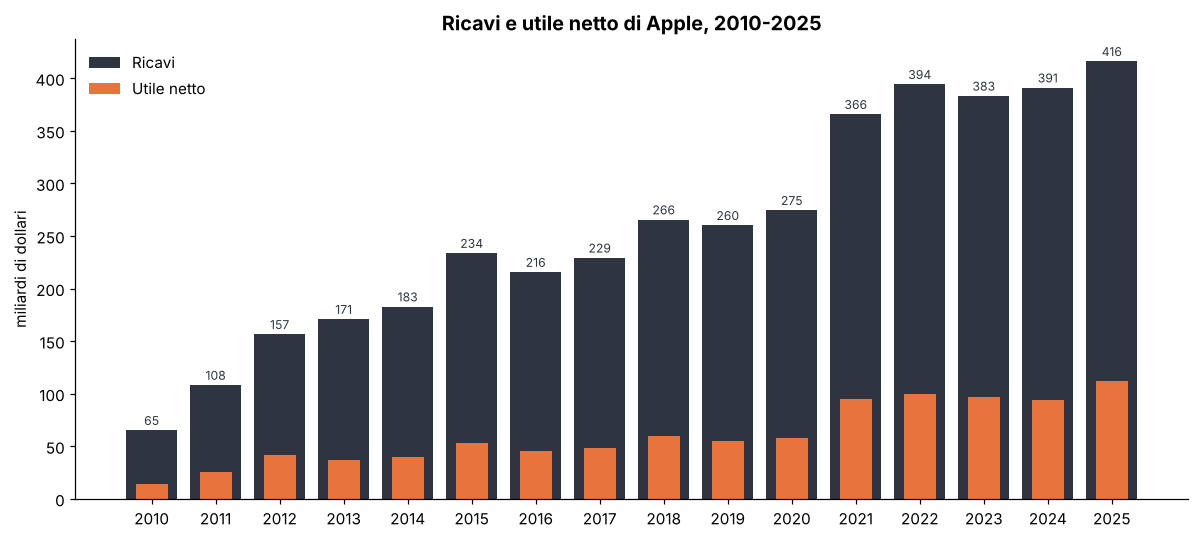

Ricavi 2010 → 2025: 65,2 mld $ → 416,2 mld $ = 6.4 volte (+13.2% all'anno in media)
Anni con ricavi in calo: 2016 (-7.7%), 2019 (-2.0%), 2023 (-2.8%)


In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(a.index, a.ricavi / 1000, color=GRAFITE, label="Ricavi")
ax.bar(a.index, a.utile_netto / 1000, color=MANDARINO, width=0.5, label="Utile netto")
for x, v in a.ricavi.items():
    ax.text(x, v / 1000 + 5, f"{v / 1000:.0f}", ha="center", fontsize=8, color=GRAFITE)
ax.set_ylabel("miliardi di dollari"); ax.set_xticks(a.index); ax.legend(frameon=False)
ax.set_title("Ricavi e utile netto di Apple, 2010-2025")
salva("01_ricavi_utile")

volte = a.loc[2025, "ricavi"] / a.loc[2010, "ricavi"]
media = (volte ** (1 / 15) - 1) * 100
cresc = a.ricavi.pct_change() * 100
print(f"Ricavi 2010 → 2025: {mld(a.loc[2010, 'ricavi'])} → {mld(a.loc[2025, 'ricavi'])} = {volte:.1f} volte (+{media:.1f}% all'anno in media)")
print("Anni con ricavi in calo:", ", ".join(f"{x} ({v:.1f}%)" for x, v in cresc[cresc < 0].items()))

📌 In 15 anni i ricavi sono diventati **6,4 volte** più grandi: da 65 a 416 miliardi di dollari.

📌 Sono scesi solo in **3 anni**: 2016, 2019 e 2023.

📌 I salti più grandi sono nei primi anni: **2011** (+66%) e **2012** (+45%), gli anni del boom di iPhone e iPad.

📌 Dopo il 2012 il salto più grande è il **2021** (+33%), l'anno del Covid e del primo iPhone 5G.

## 2️⃣ 📱 Apple dipende ancora dall'iPhone?

📌 Dal **2013** Apple divide i ricavi in 5 gruppi: iPhone, Mac, iPad, Accessori (Watch, AirPods, casa…) e Servizi.

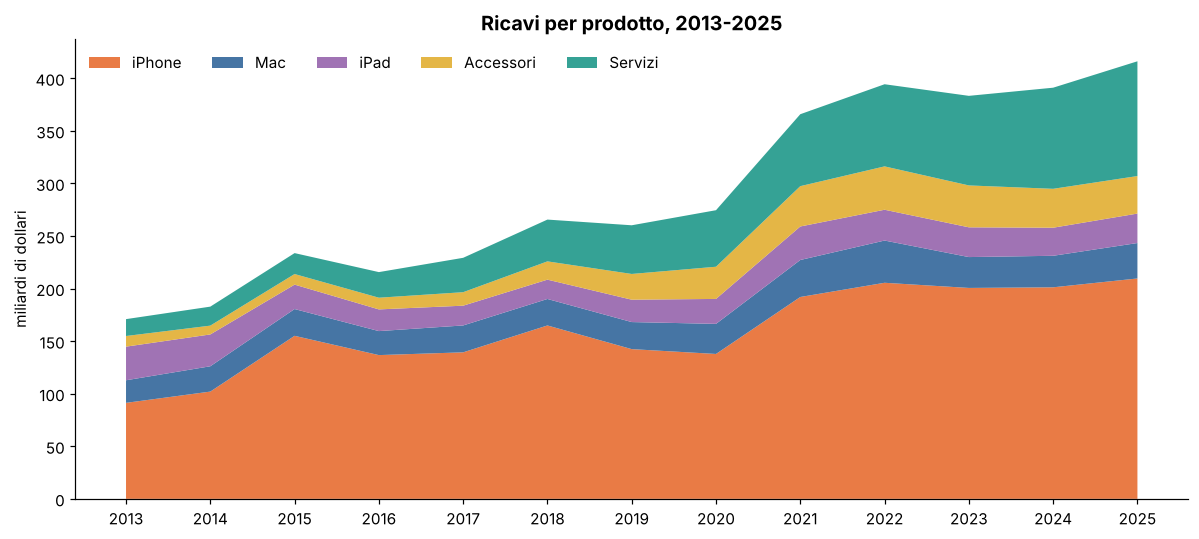

prodotto  iPhone   Mac  iPad  Accessori  Servizi
anno                                            
2013        53.4  12.6  18.7        5.9      9.4
2015        66.3  10.9   9.9        4.3      8.5
2025        50.4   8.1   6.7        8.6     26.2


In [3]:
pv = rp.pivot(index="anno", columns="prodotto", values="ricavi")[list(COL_PRODOTTO)] / 1000
fig, ax = plt.subplots(figsize=(11, 5))
ax.stackplot(pv.index, pv.T, labels=pv.columns, colors=list(COL_PRODOTTO.values()), alpha=0.95)
ax.set_ylabel("miliardi di dollari"); ax.set_xticks(pv.index)
ax.legend(loc="upper left", frameon=False, ncol=5)
ax.set_title("Ricavi per prodotto, 2013-2025")
salva("02_ricavi_prodotti")

quota = pv.div(pv.sum(axis=1), axis=0) * 100
print((quota.loc[[2013, 2015, 2025]]).round(1).to_string())

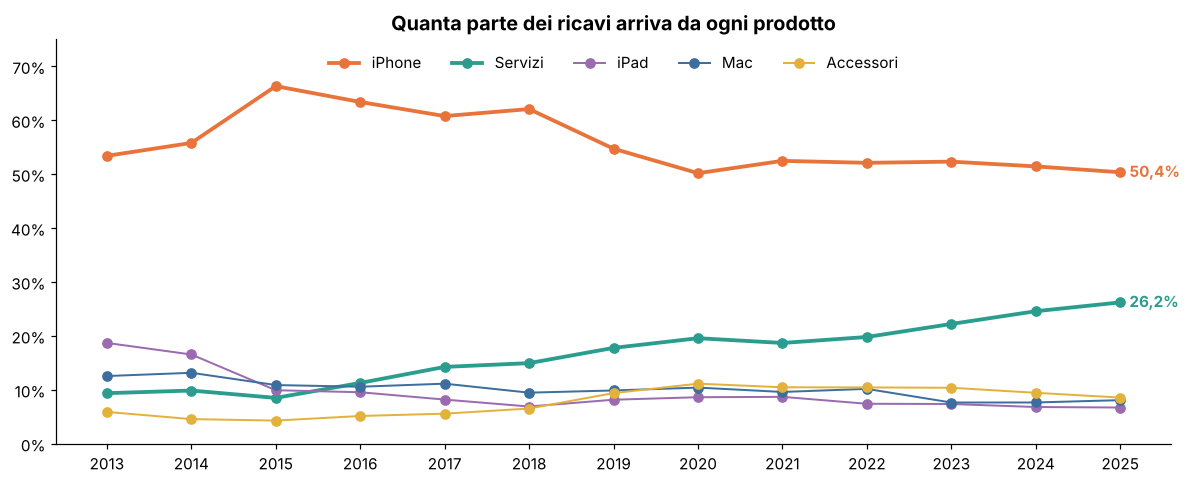

iPhone: picco 66,3% nel 2015, nel 2025 50,4%
iPad: da 18,7% a 6,7%; record di ricavi nel 2013


In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for prod in ["iPhone", "Servizi", "iPad", "Mac", "Accessori"]:
    ax.plot(quota.index, quota[prod], marker="o", lw=2.5 if prod in ("iPhone", "Servizi") else 1.3, color=COL_PRODOTTO[prod], label=prod)
    if prod in ("iPhone", "Servizi"):
        ax.annotate(pct(quota[prod].iloc[-1]), (quota.index[-1], quota[prod].iloc[-1]), xytext=(6, -3), textcoords="offset points",
                    color=COL_PRODOTTO[prod], fontweight="bold")
ax.yaxis.set_major_formatter(mt.PercentFormatter(decimals=0)); ax.set_xticks(quota.index)
ax.legend(frameon=False, ncol=5, loc="upper center"); ax.set_ylim(0, 75)
ax.set_title("Quanta parte dei ricavi arriva da ogni prodotto")
salva("03_quote_prodotti")

print(f"iPhone: picco {pct(quota.iPhone.max())} nel {quota.iPhone.idxmax()}, nel 2025 {pct(quota.iPhone.loc[2025])}")
print(f"iPad: da {pct(quota.iPad.loc[2013])} a {pct(quota.iPad.loc[2025])}; record di ricavi nel {pv.iPad.idxmax()}")

📌 L'**iPhone** porta ancora **metà** dei ricavi (50,4% nel 2025).

📌 Il picco è stato nel **2015** (66%), l'anno dell'iPhone 6 con lo schermo grande.

📌 L'**iPad** è sceso da quasi 1 dollaro su 5 (18,7%) a meno di 7 su 100: il suo anno record resta il **2013**.

📌 La dipendenza dall'iPhone è scesa, ma non perché l'iPhone vende meno: perché i **Servizi** crescono più in fretta.

## 3️⃣ ☁️ I Servizi stanno crescendo? Rendono di più?

📌 **Margine lordo** = quello che resta dopo aver pagato i costi per fare il prodotto o il servizio.

📌 Dal **2017** Apple dice i costi separati di **Prodotti** e **Servizi**.

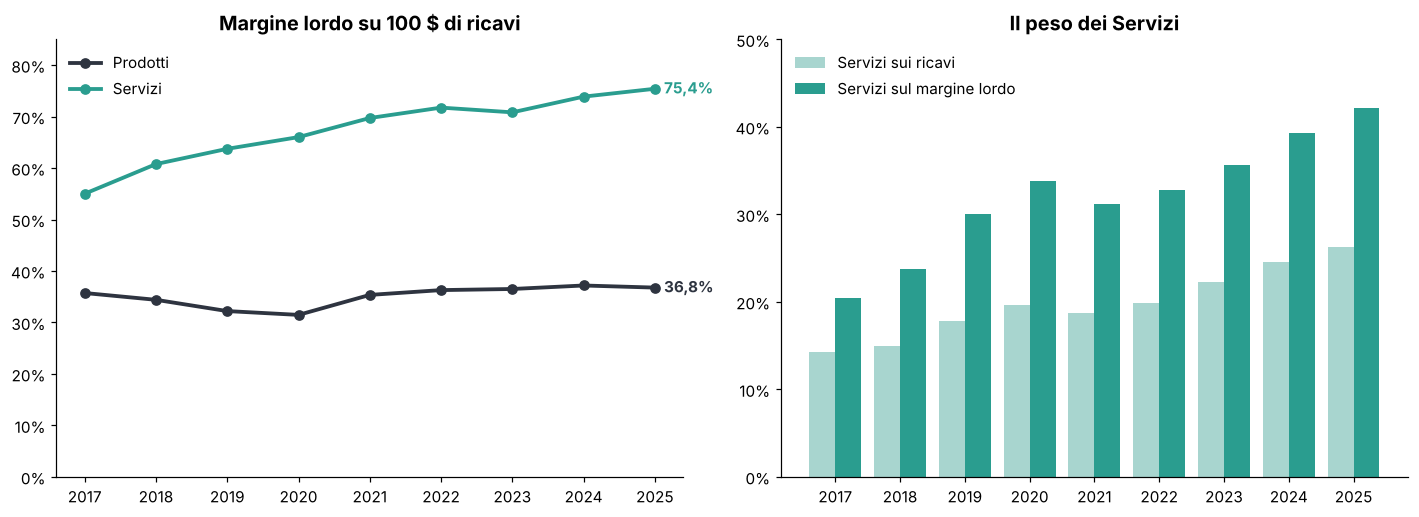

Servizi: 16.1 → 109.2 mld $ (6.8 volte)
Nel 2025 i Servizi sono 26,2% dei ricavi ma 42,2% del margine lordo


In [5]:
m = ps.assign(margine_pct=ps.margine_lordo / ps.ricavi * 100).pivot(index="anno", columns="tipo", values="margine_pct")
qm = ps.pivot(index="anno", columns="tipo", values="margine_lordo")
qm = qm.Servizi / qm.sum(axis=1) * 100
qr = ps.pivot(index="anno", columns="tipo", values="ricavi")
qr = qr.Servizi / qr.sum(axis=1) * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for tipo, col in [("Prodotti", GRAFITE), ("Servizi", TURCHESE)]:
    ax[0].plot(m.index, m[tipo], marker="o", lw=2.5, color=col, label=tipo)
    ax[0].annotate(pct(m[tipo].iloc[-1]), (m.index[-1], m[tipo].iloc[-1]), xytext=(6, -3), textcoords="offset points", color=col, fontweight="bold")
ax[0].set_ylim(0, 85); ax[0].yaxis.set_major_formatter(mt.PercentFormatter(decimals=0)); ax[0].legend(frameon=False)
ax[0].set_title("Margine lordo su 100 $ di ricavi")
ax[1].bar(qr.index - 0.2, qr, width=0.4, color="#A8D5CF", label="Servizi sui ricavi")
ax[1].bar(qm.index + 0.2, qm, width=0.4, color=TURCHESE, label="Servizi sul margine lordo")
ax[1].yaxis.set_major_formatter(mt.PercentFormatter(decimals=0)); ax[1].legend(frameon=False, loc="upper left"); ax[1].set_ylim(0, 50)
ax[1].set_title("Il peso dei Servizi")
for a_ in ax: a_.set_xticks(m.index)
salva("04_servizi_margine")

s = pv.Servizi
print(f"Servizi: {s.loc[2013]:.1f} → {s.loc[2025]:.1f} mld $ ({s.loc[2025] / s.loc[2013]:.1f} volte)")
print(f"Nel 2025 i Servizi sono {pct(qr.loc[2025])} dei ricavi ma {pct(qm.loc[2025])} del margine lordo")

📌 I **Servizi** sono passati da **16** a **109 miliardi** di dollari: quasi **7 volte** in 12 anni.

📌 Su 100 $ di Servizi restano **75 $** di margine; su 100 $ di Prodotti ne restano **37**.

📌 Per questo i Servizi sono il **26%** dei ricavi ma il **42%** del margine lordo.

📌 È anche il motivo per cui il margine di tutta Apple è salito da 38% (2019) a 47% (2025).

## 4️⃣ 🌍 In quali zone del mondo vende?

📌 Le 5 zone del bilancio: **Americhe**, **Europa** (con India, Medio Oriente e Africa), **Grande Cina** (Cina, Hong Kong, Taiwan), **Giappone**, **Resto Asia-Pacifico**.

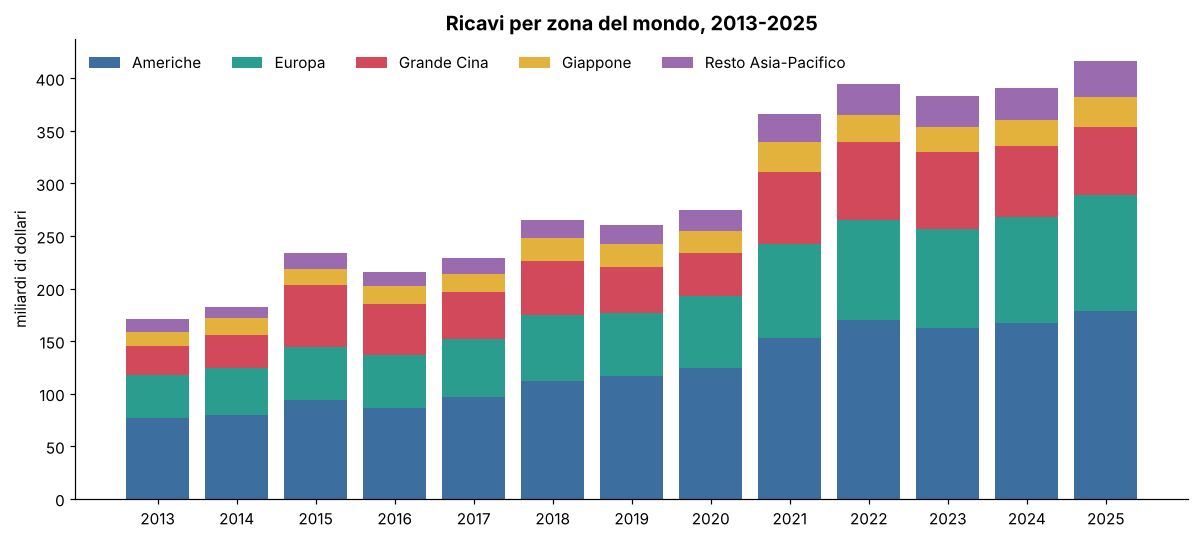

zona  Americhe  Europa  Grande Cina  Giappone  Resto Asia-Pacifico
anno                                                              
2013      45.1    24.0         15.8       8.1                  7.0
2015      40.2    21.5         25.1       6.7                  6.5
2025      42.9    26.7         15.5       6.9                  8.1


In [6]:
zv = rz.pivot(index="anno", columns="zona", values="ricavi")[list(COL_ZONA)] / 1000
fig, ax = plt.subplots(figsize=(11, 5))
basso = 0
for z in COL_ZONA:
    ax.bar(zv.index, zv[z], bottom=basso, color=COL_ZONA[z], label=z)
    basso = basso + zv[z]
ax.set_ylabel("miliardi di dollari"); ax.set_xticks(zv.index)
ax.legend(frameon=False, ncol=5, loc="upper left")
ax.set_title("Ricavi per zona del mondo, 2013-2025")
salva("05_ricavi_zone")

zq = zv.div(zv.sum(axis=1), axis=0) * 100
print(zq.loc[[2013, 2015, 2025]].round(1).to_string())

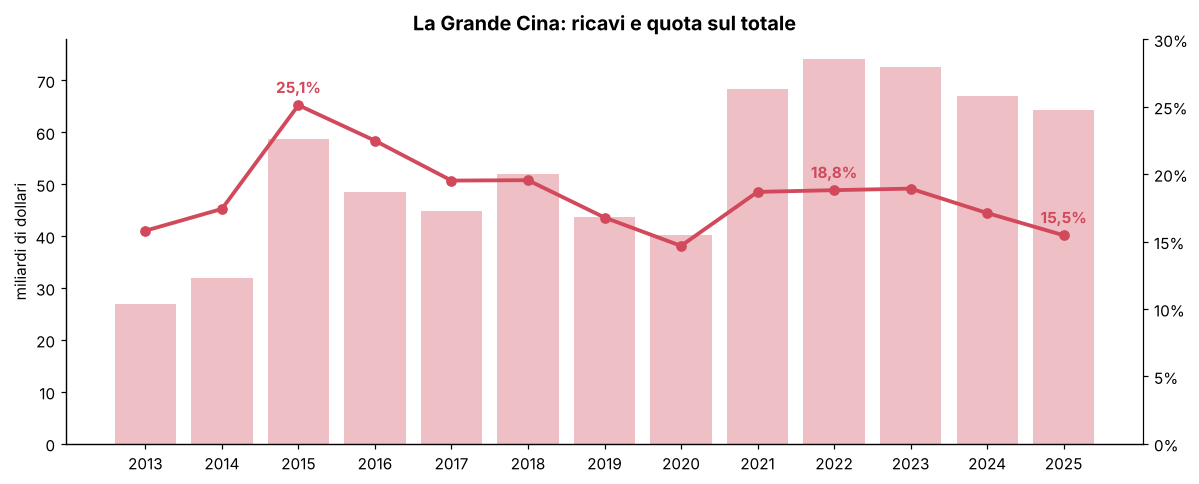

Utile operativo su 100 $ (2025): Americhe 41, Grande Cina 42, Europa 43, Resto Asia-Pacifico 43, Giappone 49
Grande Cina: 74.2 mld $ nel 2022 → 64.4 nel 2025


In [7]:
cina = zv["Grande Cina"]
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(cina.index, cina, color=CILIEGIA, alpha=0.35, label="Ricavi (mld $)")
ax1.set_ylabel("miliardi di dollari")
ax2 = ax1.twinx()
ax2.plot(zq.index, zq["Grande Cina"], color=CILIEGIA, marker="o", lw=2.5, label="Quota sui ricavi")
ax2.yaxis.set_major_formatter(mt.PercentFormatter(decimals=0)); ax2.set_ylim(0, 30); ax2.spines["right"].set_visible(True)
for x in (2015, 2022, 2025):
    ax2.annotate(pct(zq.loc[x, "Grande Cina"]), (x, zq.loc[x, "Grande Cina"]), xytext=(0, 8), textcoords="offset points",
                 ha="center", color=CILIEGIA, fontweight="bold")
ax1.set_xticks(cina.index); ax1.set_title("La Grande Cina: ricavi e quota sul totale")
salva("06_grande_cina")

margine_zona = rz[rz.anno == 2025].assign(m=lambda d: d.utile_operativo / d.ricavi * 100).set_index("zona").m.sort_values()
print("Utile operativo su 100 $ (2025):", ", ".join(f"{z} {v:.0f}" for z, v in margine_zona.items()))
print(f"Grande Cina: {cina.loc[2022]:.1f} mld $ nel 2022 → {cina.loc[2025]:.1f} nel 2025")

📌 Le **Americhe** portano più di **4 dollari su 10** (42,9%), l'**Europa** più di 1 su 4 (26,7%).

📌 La **Grande Cina** è salita fino al **25%** nel 2015 e poi è scesa al **15,5%** nel 2025.

📌 Dal 2022 al 2025 i ricavi in Grande Cina sono scesi da **74** a **64 miliardi**, mentre le altre zone crescevano.

📌 Il **Giappone** è la zona dove su 100 $ resta più utile (49 $), anche se è piccola.

## 5️⃣ 💵 Su 100 dollari di ricavi, quanti restano ad Apple?

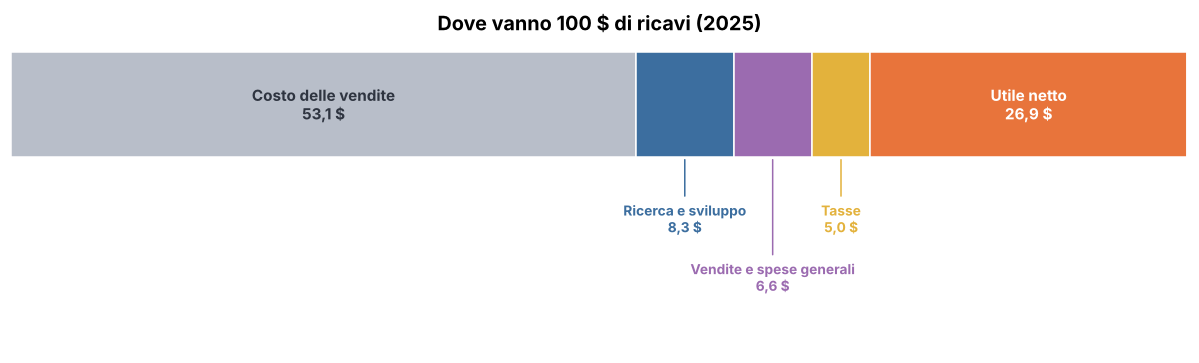

{'Costo delle vendite': np.float64(53.1), 'Ricerca e sviluppo': np.float64(8.3), 'Vendite e spese generali': np.float64(6.6), 'Tasse': np.float64(5.0), 'Utile netto': np.float64(26.9), 'Altro (interessi e altro)': np.float64(0.1)}


In [8]:
r = a.loc[2025]
voci = {"Costo delle vendite": r.costo_vendite, "Ricerca e sviluppo": r.ricerca_sviluppo,
        "Vendite e spese generali": r.spese_vendita_generali, "Tasse": r.tasse, "Utile netto": r.utile_netto}
voci = {k: v / r.ricavi * 100 for k, v in voci.items()}
voci["Altro (interessi e altro)"] = 100 - sum(voci.values())
colori = ["#B8BEC9", ACCIAIO, VIOLA, SENAPE, MANDARINO, "#DDE1E7"]
fig, ax = plt.subplots(figsize=(11, 3.4))
x, piccole = 0, 0
for (k, v), c in zip(voci.items(), colori):
    ax.barh(0, v, left=x, color=c, edgecolor="white", height=0.8)
    testo = f"{k}\n{v:.1f} $".replace(".", ",")
    if v > 20:                                   # le voci grandi: scritta dentro la barra
        ax.text(x + v / 2, 0, testo, ha="center", va="center", fontsize=10, fontweight="bold",
                color="white" if c == MANDARINO else GRAFITE)
    elif v > 1:                                  # le voci piccole: scritta sotto, una più in basso dell'altra
        y = -0.75 - 0.45 * (piccole % 2)
        ax.annotate(testo, (x + v / 2, -0.4), xytext=(x + v / 2, y), ha="center", va="top", fontsize=9, color=c,
                    fontweight="bold", arrowprops=dict(arrowstyle="-", color=c, lw=1))
        piccole += 1
    x += v
ax.set_xlim(0, 100); ax.set_ylim(-1.9, 0.5); ax.set_axis_off()
ax.set_title("Dove vanno 100 $ di ricavi (2025)")
salva("07_cento_dollari")
print({k: round(v, 1) for k, v in voci.items()})

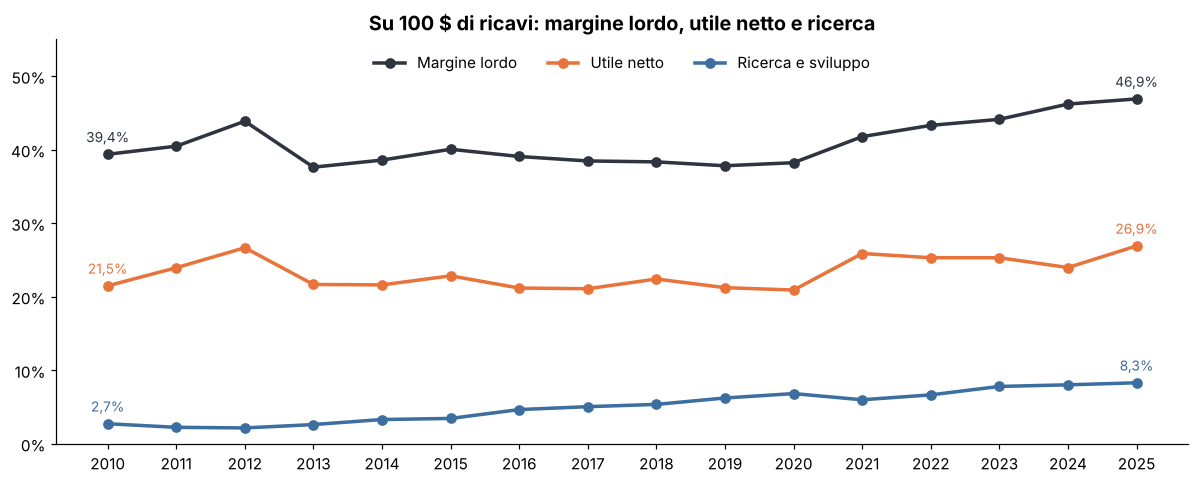

Ricerca e sviluppo: 1,8 mld $ → 34,6 mld $ (19 volte)


In [9]:
q = pd.DataFrame({"Utile netto": a.utile_netto / a.ricavi * 100, "Ricerca e sviluppo": a.ricerca_sviluppo / a.ricavi * 100,
                  "Margine lordo": a.margine_lordo / a.ricavi * 100})
fig, ax = plt.subplots(figsize=(11, 4.5))
for k, c in [("Margine lordo", GRAFITE), ("Utile netto", MANDARINO), ("Ricerca e sviluppo", ACCIAIO)]:
    ax.plot(q.index, q[k], marker="o", lw=2.3, color=c, label=k)
    for x in (2010, 2025):
        ax.annotate(pct(q.loc[x, k]), (x, q.loc[x, k]), xytext=(0, 8), textcoords="offset points", ha="center", color=c, fontsize=9)
ax.yaxis.set_major_formatter(mt.PercentFormatter(decimals=0)); ax.set_ylim(0, 55); ax.set_xticks(q.index)
ax.legend(frameon=False, ncol=3, loc="upper center")
ax.set_title("Su 100 $ di ricavi: margine lordo, utile netto e ricerca")
salva("08_margini_ricerca")
print(f"Ricerca e sviluppo: {mld(a.loc[2010, 'ricerca_sviluppo'])} → {mld(a.loc[2025, 'ricerca_sviluppo'])} "
      f"({a.loc[2025, 'ricerca_sviluppo'] / a.loc[2010, 'ricerca_sviluppo']:.0f} volte)")

📌 Su 100 $ di ricavi nel 2025: **53 $** servono a fare i prodotti, **8 $** vanno in ricerca, **7 $** in vendite e uffici, **5 $** in tasse.

📌 Alla fine restano **27 $ di utile netto**: il valore più alto dal 2010.

📌 La **ricerca e sviluppo** è passata da 1,8 a **34,6 miliardi** (19 volte): da 2,7 a 8,3 $ ogni 100 $ di ricavi.

## ✅ Conclusioni

1️⃣ 📈 Dal 2010 al 2025 i ricavi sono cresciuti **6,4 volte** (65 → 416 miliardi di $). Solo 3 anni in calo.

2️⃣ 📱 L'**iPhone** porta ancora **metà** dei ricavi, ma meno del picco del 2015 (66%).

3️⃣ ☁️ I **Servizi** sono cresciuti quasi **7 volte** e rendono il doppio dei prodotti: sono il 26% dei ricavi e il **42% del margine**.

4️⃣ 🌍 Americhe ed Europa crescono; la **Grande Cina** pesa sempre meno (dal 25% del 2015 al 15,5% del 2025).

5️⃣ 💵 Su 100 $ di ricavi restano **27 $** di utile netto, il valore più alto del periodo.

💡 **In una frase**: Apple vende ancora soprattutto iPhone, ma guadagna sempre di più dai Servizi, che rendono molto di più.

⚠️ **Limiti**

📌 Apple a volte sposta prodotti da un gruppo all'altro: per ogni anno ho usato il bilancio più recente.

📌 I 5 gruppi di prodotti e le 5 zone ci sono solo dal 2013; costi separati di Prodotti e Servizi solo dal 2017.

📌 L'utile per zona non comprende la ricerca e le spese centrali: serve per confrontare le zone, non è l'utile vero.

📌 Valori in dollari **non corretti per l'inflazione**.

📌 Il bilancio non dice quanti pezzi vende (Apple non lo pubblica più dal 2019).